In [1]:
import torch

print(torch.__version__)
print(torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

2.11.0+cu130
True
Tesla T4


PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4

Dataset
Images: 3023
Image shape: (125, 94)
Identities: 62

Split
Train: 2115
Validation: 454
Test: 454

Normalization
Mean: 0.495303213596344
Std : 0.18012015521526337

Model parameters: 401,296

STARTING TRAINING
Epoch 01/40 | Train Loss: 6.8565 | Train Acc:   0.00% | Val Loss: 6.6091 | Val Acc:   0.00% | LR: 3.00e-04
  -> New best model saved (Val Acc: 0.00%)
Epoch 02/40 | Train Loss: 6.4505 | Train Acc:   0.71% | Val Loss: 6.3974 | Val Acc:   5.51% | LR: 3.00e-04
  -> New best model saved (Val Acc: 5.51%)
Epoch 03/40 | Train Loss: 6.1896 | Train Acc:   4.73% | Val Loss: 5.9939 | Val Acc:   9.91% | LR: 3.00e-04
  -> New best model saved (Val Acc: 9.91%)
Epoch 04/40 | Train Loss: 5.8211 | Train Acc:   9.71% | Val Loss: 5.8316 | Val Acc:   7.93% | LR: 3.00e-04
Epoch 05/40 | Train Loss: 5.4542 | Train Acc:  12.97% | Val Loss: 5.3916 | Val Acc:  15.20% | LR: 3.00e-04
  -> New best model saved (Val Acc: 15.20%)
Epoch 06/40 | Train Loss: 5

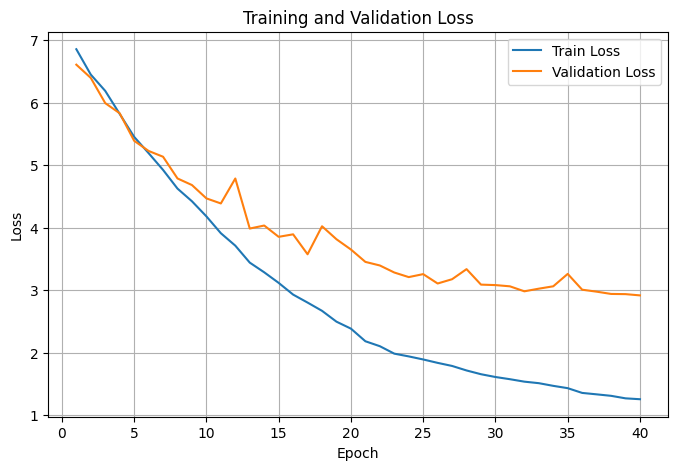

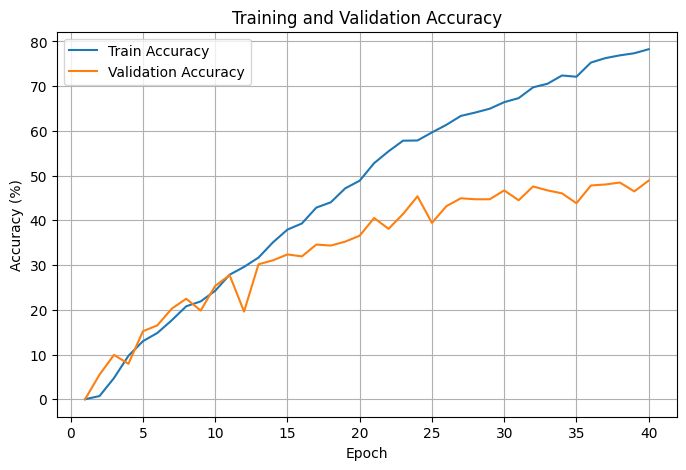

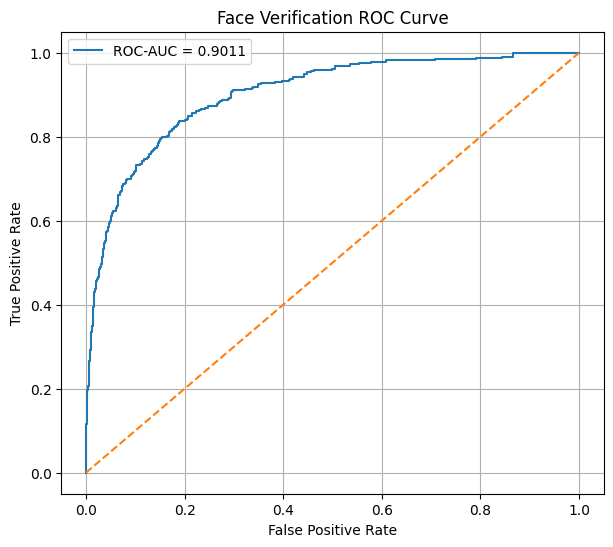


FINAL SUMMARY
Best validation accuracy : 48.90%
Test classification acc. : 53.30%
Prototype recognition acc.: 73.57%
Verification ROC-AUC      : 0.9011
Verification EER          : 17.80%
Model parameters          : 401,296
Best epoch               : 40
Checkpoint               : best_complex_face_model.pth


In [4]:
# ============================================================
# COMPLEX-VALUED LIGHTWEIGHT FACE RECOGNITION - VERSION 2
# LFW + Complex CNN + Complex ArcFace
# Google Colab / T4 GPU
# ============================================================

import os
import copy
import math
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve


# ============================================================
# 1. CONFIG
# ============================================================

SEED = 42

BATCH_SIZE = 64
MAX_EPOCHS = 40

LEARNING_RATE = 3e-4
WEIGHT_DECAY = 5e-4

EMBEDDING_DIM = 128

MIN_FACES_PER_PERSON = 20

# Early stopping
MIN_EPOCHS = 12
PATIENCE = 10
MIN_DELTA = 0.001

# ArcFace
ARCFACE_SCALE = 16.0
ARCFACE_MARGIN = 0.20

CHECKPOINT_PATH = "best_complex_face_model.pth"


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ============================================================
# 3. DEVICE
# ============================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 4. LOAD LFW
# ============================================================

lfw = fetch_lfw_people(
    min_faces_per_person=MIN_FACES_PER_PERSON,
    resize=1.0,
    color=False
)

images = lfw.images.astype(np.float32)
labels = lfw.target.astype(np.int64)
target_names = lfw.target_names.tolist()

# LFW images are normally in [0, 255]
if images.max() > 1.0:
    images /= 255.0

NUM_CLASSES = len(target_names)

print("\nDataset")
print("Images:", len(images))
print("Image shape:", images.shape[1:])
print("Identities:", NUM_CLASSES)


# ============================================================
# 5. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

all_indices = np.arange(len(images))

train_val_idx, test_idx = train_test_split(
    all_indices,
    test_size=0.15,
    random_state=SEED,
    stratify=labels
)

train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.17647,   # gives approximately 15% total validation
    random_state=SEED,
    stratify=labels[train_val_idx]
)

print("\nSplit")
print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))


# ============================================================
# 6. NORMALIZATION STATISTICS
# ============================================================

train_mean = float(images[train_idx].mean())
train_std = float(images[train_idx].std())

if train_std < 1e-6:
    train_std = 1.0

print("\nNormalization")
print("Mean:", train_mean)
print("Std :", train_std)


# ============================================================
# 7. SOBEL FILTER
# Real part  = grayscale image
# Imag part  = horizontal gradient
# ============================================================

SOBEL_X = torch.tensor(
    [
        [-1.0, 0.0, 1.0],
        [-2.0, 0.0, 2.0],
        [-1.0, 0.0, 1.0]
    ],
    dtype=torch.float32
).view(1, 1, 3, 3)


# ============================================================
# 8. DATASET
# ============================================================

class ComplexLFWDataset(Dataset):

    def __init__(
        self,
        images,
        labels,
        mean,
        std,
        augment=False
    ):
        self.images = torch.from_numpy(images)
        self.labels = torch.from_numpy(labels)

        self.mean = mean
        self.std = std

        self.augment = augment

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        # [H, W] -> [1, H, W]
        x = self.images[idx].clone().unsqueeze(0)

        h, w = x.shape[1], x.shape[2]

        # ----------------------------------------------------
        # Data augmentation
        # ----------------------------------------------------

        if self.augment:

            # Horizontal flip
            if random.random() < 0.5:
                x = torch.flip(x, dims=[2])

            # Small translation
            if random.random() < 0.30:

                x_pad = F.pad(
                    x.unsqueeze(0),
                    (2, 2, 2, 2),
                    mode="reflect"
                ).squeeze(0)

                top = random.randint(0, 4)
                left = random.randint(0, 4)

                x = x_pad[
                    :,
                    top:top + h,
                    left:left + w
                ]

            # Small brightness perturbation
            if random.random() < 0.30:

                factor = random.uniform(0.9, 1.1)
                x = x * factor

            # Small Gaussian noise
            if random.random() < 0.20:

                noise = 0.01 * torch.randn_like(x)
                x = x + noise

        x = x.clamp(0.0, 1.0)

        # ----------------------------------------------------
        # Real component
        # ----------------------------------------------------

        real = (x - self.mean) / self.std

        # ----------------------------------------------------
        # Imaginary component
        # Horizontal Sobel gradient
        # ----------------------------------------------------

        gradient = F.conv2d(
            x.unsqueeze(0),
            SOBEL_X,
            padding=1
        ).squeeze(0)

        gradient_std = gradient.flatten().std()

        if gradient_std < 1e-6:
            gradient_std = torch.tensor(1.0)

        imag = gradient / (3.0 * gradient_std)
        imag = imag.clamp(-1.0, 1.0)

        # ----------------------------------------------------
        # Complex image
        # ----------------------------------------------------

        complex_image = torch.complex(real, imag)

        label = self.labels[idx]

        return complex_image, label


# ============================================================
# 9. DATASETS
# ============================================================

train_dataset = ComplexLFWDataset(
    images[train_idx],
    labels[train_idx],
    train_mean,
    train_std,
    augment=True
)

val_dataset = ComplexLFWDataset(
    images[val_idx],
    labels[val_idx],
    train_mean,
    train_std,
    augment=False
)

test_dataset = ComplexLFWDataset(
    images[test_idx],
    labels[test_idx],
    train_mean,
    train_std,
    augment=False
)


# ============================================================
# 10. DATALOADERS
# ============================================================

NUM_WORKERS = 2 if torch.cuda.is_available() else 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)


# ============================================================
# 11. COMPLEX CONVOLUTION
#
# z = zr + i zi
# W = Wr + i Wi
#
# Wz =
# (Wr*zr - Wi*zi)
# +
# i(Wr*zi + Wi*zr)
# ============================================================

class ComplexConv2d(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=True
    ):
        super().__init__()

        self.real_weight = nn.Parameter(
            torch.empty(
                out_channels,
                in_channels,
                kernel_size,
                kernel_size
            )
        )

        self.imag_weight = nn.Parameter(
            torch.empty(
                out_channels,
                in_channels,
                kernel_size,
                kernel_size
            )
        )

        if bias:
            self.real_bias = nn.Parameter(
                torch.zeros(out_channels)
            )

            self.imag_bias = nn.Parameter(
                torch.zeros(out_channels)
            )
        else:
            self.register_parameter("real_bias", None)
            self.register_parameter("imag_bias", None)

        nn.init.kaiming_normal_(
            self.real_weight,
            mode="fan_out",
            nonlinearity="relu"
        )

        nn.init.kaiming_normal_(
            self.imag_weight,
            mode="fan_out",
            nonlinearity="relu"
        )

        # Keep complex magnitude controlled
        self.real_weight.data.div_(math.sqrt(2))
        self.imag_weight.data.div_(math.sqrt(2))

        self.stride = stride
        self.padding = padding

    def forward(self, z):

        zr = z.real
        zi = z.imag

        real = (
            F.conv2d(
                zr,
                self.real_weight,
                self.real_bias,
                self.stride,
                self.padding
            )
            -
            F.conv2d(
                zi,
                self.imag_weight,
                self.imag_bias,
                self.stride,
                self.padding
            )
        )

        imag = (
            F.conv2d(
                zr,
                self.imag_weight,
                None,
                self.stride,
                self.padding
            )
            +
            F.conv2d(
                zi,
                self.real_weight,
                None,
                self.stride,
                self.padding
            )
        )

        return torch.complex(real, imag)


# ============================================================
# 12. COMPLEX BATCH NORMALIZATION
# ============================================================

class ComplexBatchNorm2d(nn.Module):

    def __init__(self, channels):
        super().__init__()

        # Normalize real and imaginary parts independently
        self.bn_real = nn.BatchNorm2d(
            channels,
            affine=False
        )

        self.bn_imag = nn.BatchNorm2d(
            channels,
            affine=False
        )

        # Complex learnable gamma
        self.gamma_real = nn.Parameter(
            torch.ones(channels)
        )

        self.gamma_imag = nn.Parameter(
            torch.zeros(channels)
        )

        # Complex learnable beta
        self.beta_real = nn.Parameter(
            torch.zeros(channels)
        )

        self.beta_imag = nn.Parameter(
            torch.zeros(channels)
        )

    def forward(self, z):

        xr = self.bn_real(z.real)
        xi = self.bn_imag(z.imag)

        gr = self.gamma_real[None, :, None, None]
        gi = self.gamma_imag[None, :, None, None]

        br = self.beta_real[None, :, None, None]
        bi = self.beta_imag[None, :, None, None]

        real = gr * xr - gi * xi + br
        imag = gr * xi + gi * xr + bi

        return torch.complex(real, imag)


# ============================================================
# 13. COMPLEX ReLU
# ============================================================

class ComplexReLU(nn.Module):

    def forward(self, z):

        return torch.complex(
            F.relu(z.real),
            F.relu(z.imag)
        )


# ============================================================
# 14. COMPLEX AVERAGE POOLING
#
# PyTorch does not support ordinary avg_pool2d directly
# on complex tensors, so we apply it to both components.
# ============================================================

class ComplexAvgPool2d(nn.Module):

    def __init__(self, kernel_size=2):

        super().__init__()

        self.kernel_size = kernel_size

    def forward(self, z):

        real = F.avg_pool2d(
            z.real,
            self.kernel_size
        )

        imag = F.avg_pool2d(
            z.imag,
            self.kernel_size
        )

        return torch.complex(real, imag)


# ============================================================
# 15. COMPLEX DROPOUT
# Same mask is applied to real and imaginary parts.
# ============================================================

class ComplexDropout(nn.Module):

    def __init__(self, p=0.15):

        super().__init__()

        self.p = p

    def forward(self, z):

        if not self.training or self.p == 0:
            return z

        mask = F.dropout(
            torch.ones_like(z.real),
            p=self.p,
            training=True
        )

        return z * mask


# ============================================================
# 16. COMPLEX RESIDUAL BLOCK
# ============================================================

class ComplexResidualBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        stride=1
    ):
        super().__init__()

        self.conv1 = ComplexConv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=stride,
            padding=1
        )

        self.bn1 = ComplexBatchNorm2d(
            out_channels
        )

        self.conv2 = ComplexConv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            stride=1,
            padding=1
        )

        self.bn2 = ComplexBatchNorm2d(
            out_channels
        )

        self.activation = ComplexReLU()

        # Residual shortcut
        if (
            in_channels != out_channels
            or stride != 1
        ):

            self.shortcut = nn.Sequential(

                ComplexConv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride,
                    padding=0
                ),

                ComplexBatchNorm2d(
                    out_channels
                )
            )

        else:

            self.shortcut = nn.Identity()

    def forward(self, z):

        identity = self.shortcut(z)

        out = self.conv1(z)
        out = self.bn1(out)
        out = self.activation(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity
        out = self.activation(out)

        return out


# ============================================================
# 17. COMPLEX LINEAR
# ============================================================

class ComplexLinear(nn.Module):

    def __init__(
        self,
        in_features,
        out_features,
        bias=True
    ):
        super().__init__()

        self.real_weight = nn.Parameter(
            torch.empty(
                out_features,
                in_features
            )
        )

        self.imag_weight = nn.Parameter(
            torch.empty(
                out_features,
                in_features
            )
        )

        if bias:

            self.real_bias = nn.Parameter(
                torch.zeros(out_features)
            )

            self.imag_bias = nn.Parameter(
                torch.zeros(out_features)
            )

        else:

            self.register_parameter(
                "real_bias",
                None
            )

            self.register_parameter(
                "imag_bias",
                None
            )

        nn.init.kaiming_normal_(
            self.real_weight,
            nonlinearity="relu"
        )

        nn.init.kaiming_normal_(
            self.imag_weight,
            nonlinearity="relu"
        )

        self.real_weight.data.div_(math.sqrt(2))
        self.imag_weight.data.div_(math.sqrt(2))

    def forward(self, z):

        zr = z.real
        zi = z.imag

        real = (
            F.linear(
                zr,
                self.real_weight,
                self.real_bias
            )
            -
            F.linear(
                zi,
                self.imag_weight,
                self.imag_bias
            )
        )

        imag = (
            F.linear(
                zr,
                self.imag_weight,
                None
            )
            +
            F.linear(
                zi,
                self.real_weight,
                None
            )
        )

        return torch.complex(real, imag)


# ============================================================
# 18. COMPLEX L2 NORMALIZATION
# ============================================================

def complex_l2_normalize(z, eps=1e-8):

    norm = torch.sqrt(
        (
            z.real.square()
            +
            z.imag.square()
        )
        .sum(dim=1, keepdim=True)
        .clamp_min(eps)
    )

    return z / norm


# ============================================================
# 19. LIGHTWEIGHT COMPLEX FACE NETWORK
#
# 1 -> 16 -> 24 -> 48 -> 64
#
# Much smaller than the previous network.
# ============================================================

class ComplexFaceNet(nn.Module):

    def __init__(
        self,
        embedding_dim=128
    ):
        super().__init__()

        self.stem = nn.Sequential(

            ComplexConv2d(
                1,
                16,
                kernel_size=3,
                stride=1,
                padding=1
            ),

            ComplexBatchNorm2d(16),

            ComplexReLU(),

            ComplexAvgPool2d(2)
        )

        self.blocks = nn.Sequential(

            ComplexResidualBlock(
                16,
                24,
                stride=2
            ),

            ComplexResidualBlock(
                24,
                48,
                stride=2
            ),

            ComplexResidualBlock(
                48,
                64,
                stride=2
            ),

            ComplexResidualBlock(
                64,
                64,
                stride=1
            )
        )

        self.dropout = ComplexDropout(
            p=0.15
        )

        self.embedding = ComplexLinear(
            64,
            embedding_dim,
            bias=True
        )

    def forward(self, z):

        z = self.stem(z)

        z = self.blocks(z)

        # Complex global average pooling
        real = F.adaptive_avg_pool2d(
            z.real,
            (1, 1)
        ).flatten(1)

        imag = F.adaptive_avg_pool2d(
            z.imag,
            (1, 1)
        ).flatten(1)

        z = torch.complex(
            real,
            imag
        )

        z = self.dropout(z)

        z = self.embedding(z)

        z = complex_l2_normalize(z)

        return z


# ============================================================
# 20. COMPLEX ARCFACE
#
# Class weights are also complex:
#
# W_class = Wr + iWi
#
# Similarity is computed in the combined real/imaginary
# feature space.
# ============================================================

class ComplexArcFace(nn.Module):

    def __init__(
        self,
        num_classes,
        embedding_dim,
        scale=16.0,
        margin=0.20
    ):
        super().__init__()

        self.real_weight = nn.Parameter(
            torch.empty(
                num_classes,
                embedding_dim
            )
        )

        self.imag_weight = nn.Parameter(
            torch.empty(
                num_classes,
                embedding_dim
            )
        )

        nn.init.normal_(
            self.real_weight,
            mean=0.0,
            std=0.02
        )

        nn.init.normal_(
            self.imag_weight,
            mean=0.0,
            std=0.02
        )

        self.scale = scale
        self.margin = margin

        self.cos_m = math.cos(margin)
        self.sin_m = math.sin(margin)

    def forward(self, z, labels):

        z = complex_l2_normalize(z)

        # Normalize complex class weights
        weight_norm = torch.sqrt(
            (
                self.real_weight.square()
                +
                self.imag_weight.square()
            )
            .sum(dim=1, keepdim=True)
            .clamp_min(1e-8)
        )

        wr = self.real_weight / weight_norm
        wi = self.imag_weight / weight_norm

        # Complex inner product -> real cosine similarity
        cosine = (
            F.linear(z.real, wr)
            +
            F.linear(z.imag, wi)
        )

        cosine = cosine.clamp(
            -1.0 + 1e-7,
            1.0 - 1e-7
        )

        sine = torch.sqrt(
            (1.0 - cosine.square())
            .clamp_min(1e-7)
        )

        phi = (
            cosine * self.cos_m
            -
            sine * self.sin_m
        )

        one_hot = F.one_hot(
            labels,
            num_classes=cosine.size(1)
        ).to(cosine.dtype)

        logits = (
            one_hot * phi
            +
            (1.0 - one_hot) * cosine
        )

        return logits * self.scale


# ============================================================
# 21. CREATE MODEL
# ============================================================

model = ComplexFaceNet(
    embedding_dim=EMBEDDING_DIM
).to(DEVICE)

arcface = ComplexArcFace(
    NUM_CLASSES,
    EMBEDDING_DIM,
    scale=ARCFACE_SCALE,
    margin=ARCFACE_MARGIN
).to(DEVICE)


# ============================================================
# 22. PARAMETER COUNT
# ============================================================

total_params = sum(
    p.numel()
    for p in list(model.parameters())
    + list(arcface.parameters())
)

print("\nModel parameters:", f"{total_params:,}")


# ============================================================
# 23. OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(
    list(model.parameters())
    + list(arcface.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# 24. LR SCHEDULER
# ============================================================

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)


# ============================================================
# 25. TRAIN / EVAL FUNCTION
# ============================================================

def run_epoch(loader, training=True):

    if training:

        model.train()
        arcface.train()

    else:

        model.eval()
        arcface.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images_batch, labels_batch in loader:

        images_batch = images_batch.to(
            DEVICE,
            non_blocking=True
        )

        labels_batch = labels_batch.to(
            DEVICE,
            non_blocking=True
        )

        if training:

            optimizer.zero_grad(
                set_to_none=True
            )

        with torch.set_grad_enabled(training):

            embeddings = model(
                images_batch
            )

            logits = arcface(
                embeddings,
                labels_batch
            )

            loss = F.cross_entropy(
                logits,
                labels_batch,
                label_smoothing=0.05
            )

            # Safety check
            if not torch.isfinite(loss):

                raise RuntimeError(
                    f"Non-finite loss detected: {loss.item()}"
                )

            if training:

                loss.backward()

                # Gradient clipping
                torch.nn.utils.clip_grad_norm_(
                    list(model.parameters())
                    + list(arcface.parameters()),
                    max_norm=5.0
                )

                optimizer.step()

        running_loss += (
            loss.item()
            * labels_batch.size(0)
        )

        predictions = logits.argmax(dim=1)

        correct += (
            predictions == labels_batch
        ).sum().item()

        total += labels_batch.size(0)

    epoch_loss = running_loss / total
    epoch_acc = 100.0 * correct / total

    return epoch_loss, epoch_acc


# ============================================================
# 26. TRAINING
# ============================================================

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "lr": []
}

best_val_acc = -float("inf")
best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

best_model_state = None
best_arcface_state = None

print("\n" + "=" * 70)
print("STARTING TRAINING")
print("=" * 70)


for epoch in range(1, MAX_EPOCHS + 1):

    train_loss, train_acc = run_epoch(
        train_loader,
        training=True
    )

    val_loss, val_acc = run_epoch(
        val_loader,
        training=False
    )

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    history["lr"].append(current_lr)

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:6.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:6.2f}% | "
        f"LR: {current_lr:.2e}"
    )

    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    improved = False

    if val_acc > best_val_acc + MIN_DELTA:

        improved = True

    elif (
        abs(val_acc - best_val_acc) <= MIN_DELTA
        and val_loss < best_val_loss
    ):

        improved = True

    if improved:

        best_val_acc = val_acc
        best_val_loss = val_loss
        best_epoch = epoch

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        best_arcface_state = copy.deepcopy(
            arcface.state_dict()
        )

        # IMPORTANT:
        # Only tensors + simple Python values are saved.
        # This avoids the previous torch.load / NumPy error.

        torch.save(
            {
                "model_state": best_model_state,
                "arcface_state": best_arcface_state,
                "best_val_acc": float(best_val_acc),
                "best_val_loss": float(best_val_loss),
                "best_epoch": int(best_epoch)
            },
            CHECKPOINT_PATH
        )

        epochs_without_improvement = 0

        print(
            f"  -> New best model saved "
            f"(Val Acc: {best_val_acc:.2f}%)"
        )

    else:

        epochs_without_improvement += 1

    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------

    if (
        epoch >= MIN_EPOCHS
        and
        epochs_without_improvement >= PATIENCE
    ):

        print(
            f"\nEarly stopping at epoch {epoch}."
        )

        print(
            f"Best epoch: {best_epoch}"
        )

        print(
            f"Best validation accuracy: "
            f"{best_val_acc:.2f}%"
        )

        break


print("\nTraining finished.")
print(
    f"Best validation accuracy: "
    f"{best_val_acc:.2f}%"
)
print(
    f"Best epoch: {best_epoch}"
)


# ============================================================
# 27. LOAD BEST CHECKPOINT
# ============================================================
#
# weights_only=True is now safe because the checkpoint contains
# only tensors + simple Python values.
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state"]
)

arcface.load_state_dict(
    checkpoint["arcface_state"]
)

print(
    "\nBest checkpoint loaded successfully."
)


# ============================================================
# 28. TEST CLASSIFICATION
# ============================================================

test_loss, test_acc = run_epoch(
    test_loader,
    training=False
)

print("\n" + "=" * 70)
print("TEST RESULTS")
print("=" * 70)

print(
    f"Test Loss     : {test_loss:.4f}"
)

print(
    f"Test Accuracy : {test_acc:.2f}%"
)


# ============================================================
# 29. EXTRACT EMBEDDINGS
# ============================================================

@torch.no_grad()
def extract_embeddings(loader):

    model.eval()

    all_features = []
    all_labels = []

    for batch_images, batch_labels in loader:

        batch_images = batch_images.to(
            DEVICE,
            non_blocking=True
        )

        embeddings = model(
            batch_images
        )

        # Convert complex vector to real vector
        # [real | imaginary]
        features = torch.cat(
            [
                embeddings.real,
                embeddings.imag
            ],
            dim=1
        )

        features = F.normalize(
            features,
            p=2,
            dim=1
        )

        all_features.append(
            features.cpu()
        )

        all_labels.append(
            batch_labels
        )

    return (
        torch.cat(all_features),
        torch.cat(all_labels)
    )


train_embeddings, train_embed_labels = extract_embeddings(
    DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS
    )
)

test_embeddings, test_embed_labels = extract_embeddings(
    test_loader
)


# ============================================================
# 30. PROTOTYPE-BASED FACE RECOGNITION
# ============================================================

prototypes = []

for class_id in range(NUM_CLASSES):

    class_embeddings = train_embeddings[
        train_embed_labels == class_id
    ]

    prototype = class_embeddings.mean(
        dim=0,
        keepdim=True
    )

    prototype = F.normalize(
        prototype,
        p=2,
        dim=1
    )

    prototypes.append(
        prototype
    )

prototypes = torch.cat(
    prototypes,
    dim=0
)

similarity = (
    test_embeddings
    @
    prototypes.T
)

prototype_predictions = similarity.argmax(
    dim=1
)

prototype_accuracy = (
    prototype_predictions == test_embed_labels
).float().mean().item() * 100

print(
    f"\nPrototype recognition accuracy: "
    f"{prototype_accuracy:.2f}%"
)


# ============================================================
# 31. VERIFICATION
#
# Positive pair  = same person
# Negative pair  = different persons
# ============================================================

def create_verification_pairs(
    embeddings,
    labels,
    num_pairs=4000,
    seed=42
):

    rng = np.random.default_rng(seed)

    labels_np = labels.numpy()

    class_to_indices = {}

    for class_id in np.unique(labels_np):

        indices = np.where(
            labels_np == class_id
        )[0]

        if len(indices) >= 2:

            class_to_indices[class_id] = indices

    valid_classes = list(
        class_to_indices.keys()
    )

    pair_a = []
    pair_b = []
    pair_labels = []

    # --------------------------------------------------------
    # Positive pairs
    # --------------------------------------------------------

    num_positive = num_pairs // 2

    while len(pair_labels) < num_positive:

        class_id = rng.choice(
            valid_classes
        )

        inds = class_to_indices[
            class_id
        ]

        i, j = rng.choice(
            inds,
            size=2,
            replace=False
        )

        pair_a.append(
            embeddings[i]
        )

        pair_b.append(
            embeddings[j]
        )

        pair_labels.append(1)

    # --------------------------------------------------------
    # Negative pairs
    # --------------------------------------------------------

    while len(pair_labels) < num_pairs:

        c1, c2 = rng.choice(
            valid_classes,
            size=2,
            replace=False
        )

        i = rng.choice(
            class_to_indices[c1]
        )

        j = rng.choice(
            class_to_indices[c2]
        )

        pair_a.append(
            embeddings[i]
        )

        pair_b.append(
            embeddings[j]
        )

        pair_labels.append(0)

    pair_a = torch.stack(pair_a)
    pair_b = torch.stack(pair_b)

    # Cosine similarity
    scores = (
        pair_a * pair_b
    ).sum(dim=1).numpy()

    pair_labels = np.array(
        pair_labels
    )

    return scores, pair_labels


verification_scores, verification_labels = (
    create_verification_pairs(
        test_embeddings,
        test_embed_labels,
        num_pairs=4000,
        seed=SEED
    )
)


# ============================================================
# 32. ROC-AUC
# ============================================================

auc = roc_auc_score(
    verification_labels,
    verification_scores
)

fpr, tpr, thresholds = roc_curve(
    verification_labels,
    verification_scores
)

fnr = 1.0 - tpr

eer_index = np.argmin(
    np.abs(fpr - fnr)
)

eer = (
    fpr[eer_index]
    +
    fnr[eer_index]
) / 2.0

print("\n" + "=" * 70)
print("FACE VERIFICATION")
print("=" * 70)

print(
    f"ROC-AUC : {auc:.4f}"
)

print(
    f"EER     : {eer * 100:.2f}%"
)


# ============================================================
# 33. TRAINING CURVES
# ============================================================

epochs_done = len(
    history["train_loss"]
)

epoch_numbers = np.arange(
    1,
    epochs_done + 1
)


# Loss curve
plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epoch_numbers,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()


# Accuracy curve
plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    history["train_acc"],
    label="Train Accuracy"
)

plt.plot(
    epoch_numbers,
    history["val_acc"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()


# ROC curve
plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Face Verification ROC Curve")
plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 34. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL SUMMARY")
print("=" * 70)

print(
    f"Best validation accuracy : {best_val_acc:.2f}%"
)

print(
    f"Test classification acc. : {test_acc:.2f}%"
)

print(
    f"Prototype recognition acc.: {prototype_accuracy:.2f}%"
)

print(
    f"Verification ROC-AUC      : {auc:.4f}"
)

print(
    f"Verification EER          : {eer * 100:.2f}%"
)

print(
    f"Model parameters          : {total_params:,}"
)

print(
    f"Best epoch               : {best_epoch}"
)

print(
    f"Checkpoint               : {CHECKPOINT_PATH}"
)

COMPLEX-VALUED FACE RECOGNITION PIPELINE
PyTorch Version : 2.11.0+cu130
Compute Device  : cuda
GPU Model       : Tesla T4

Fetching LFW dataset from scikit-learn repository...
Loaded Identities : 62
Total Face Images : 3023
Raw Image Shape   : (125, 94)

Dataset Partitioning:
  Training Set   : 2115 samples
  Validation Set : 454 samples
  Testing Set    : 454 samples

Total Trainable Parameters: 5,678,528

Starting Training Execution...
Epoch 01/40 | Train Loss: 14.5490 | Train Acc:   2.89% | Val Loss: 13.7534 | Val Acc:   3.96% | LR: 4.99e-04
  -> New optimal checkpoint saved (Val Acc: 3.96%)
Epoch 02/40 | Train Loss: 12.6425 | Train Acc:   9.14% | Val Loss: 13.9952 | Val Acc:   5.95% | LR: 4.97e-04
  -> New optimal checkpoint saved (Val Acc: 5.95%)
Epoch 03/40 | Train Loss: 10.5151 | Train Acc:  16.67% | Val Loss: 11.6843 | Val Acc:   7.93% | LR: 4.93e-04
  -> New optimal checkpoint saved (Val Acc: 7.93%)
Epoch 04/40 | Train Loss: 8.2898 | Train Acc:  23.20% | Val Loss: 12.0534 | Va

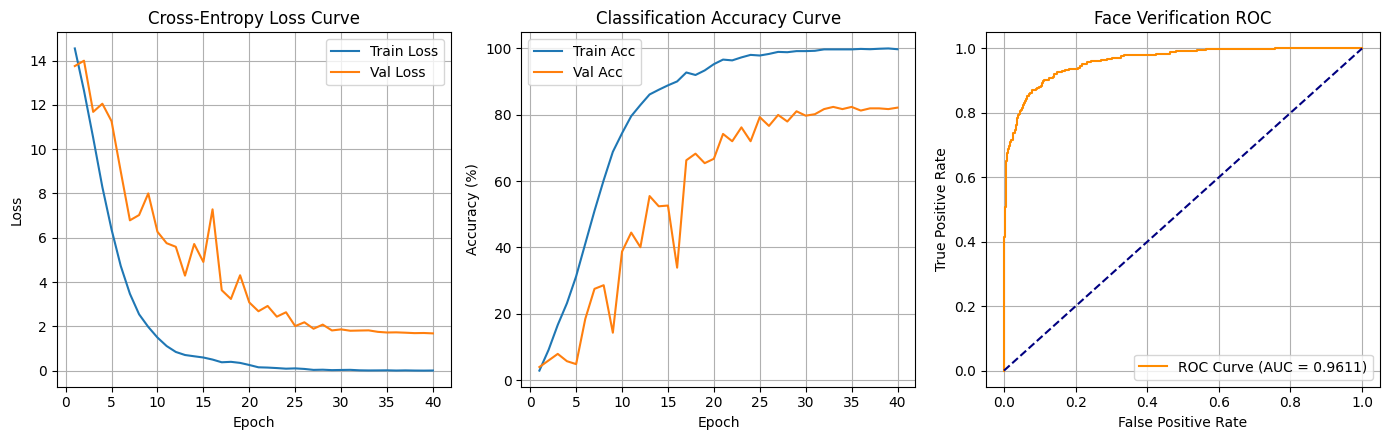


FINAL BENCHMARK RESULTS
Total Model Parameters    : 5,678,528
Best Validation Accuracy  : 82.38% (Epoch 33)
Test Set Accuracy         : 85.90%
Prototype Recognition Acc : 93.17%
Verification ROC-AUC      : 0.9611
Verification EER          : 10.85%
Model Checkpoint Path     : best_complex_face_model.pth


In [6]:
# ================================================================
# HIGH-ACCURACY FULLY COMPLEX-VALUED FACE RECOGNITION (LFW)
# Architecture: Complex Residual CNN + Complex ArcFace Head
# Target Platform: Google Colab (Tesla T4 / A100 GPU)
# ================================================================

import os
import copy
import math
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve

# ================================================================
# 1. CONFIGURATION
# ================================================================

SEED = 42
BATCH_SIZE = 32
MAX_EPOCHS = 40

LEARNING_RATE = 5e-4
WEIGHT_DECAY = 1e-4

EMBEDDING_DIM = 256
MIN_FACES_PER_PERSON = 20

# Optimized ArcFace parameters
ARCFACE_SCALE = 32.0
ARCFACE_MARGIN = 0.35

IMAGE_SIZE = (112, 112)
CHECKPOINT_PATH = "best_complex_face_model.pth"

# ================================================================
# 2. REPRODUCIBILITY & DEVICE SETUP
# ================================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 70)
print("COMPLEX-VALUED FACE RECOGNITION PIPELINE")
print("=" * 70)
print("PyTorch Version :", torch.__version__)
print("Compute Device  :", DEVICE)
if torch.cuda.is_available():
    print("GPU Model       :", torch.cuda.get_device_name(0))

# ================================================================
# 3. AUTOMATIC LFW DATASET DOWNLOAD
# ================================================================

print("\nFetching LFW dataset from scikit-learn repository...")
lfw = fetch_lfw_people(
    min_faces_per_person=MIN_FACES_PER_PERSON,
    resize=1.0,
    color=False,
    funneled=True,
    download_if_missing=True
)

images_raw = lfw.images.astype(np.float32)
labels_raw = lfw.target.astype(np.int64)
target_names = lfw.target_names.tolist()
NUM_CLASSES = len(target_names)

# Normalize grayscale pixel values to [0, 1]
if images_raw.max() > 1.0:
    images_raw /= 255.0

print(f"Loaded Identities : {NUM_CLASSES}")
print(f"Total Face Images : {len(images_raw)}")
print(f"Raw Image Shape   : {images_raw.shape[1:]}")

# ================================================================
# 4. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ================================================================

indices = np.arange(len(images_raw))

train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.15,
    random_state=SEED,
    stratify=labels_raw
)

train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.17647,  # Produces a clean 70% / 15% / 15% overall split
    random_state=SEED,
    stratify=labels_raw[train_val_idx]
)

print("\nDataset Partitioning:")
print(f"  Training Set   : {len(train_idx)} samples")
print(f"  Validation Set : {len(val_idx)} samples")
print(f"  Testing Set    : {len(test_idx)} samples")

# Global intensity standardization computed strictly on the training partition
train_mean = float(images_raw[train_idx].mean())
train_std = float(images_raw[train_idx].std())
if train_std < 1e-6:
    train_std = 1.0

# ================================================================
# 5. COMPLEX INPUT TRANSFORMATION & DATASET
# ================================================================

# 2D horizontal and vertical Sobel gradient filters
SOBEL_X = torch.tensor(
    [[-1.0, 0.0, 1.0], [-2.0, 0.0, 2.0], [-1.0, 0.0, 1.0]],
    dtype=torch.float32
).view(1, 1, 3, 3)

SOBEL_Y = torch.tensor(
    [[-1.0, -2.0, -1.0], [0.0, 0.0, 0.0], [1.0, 2.0, 1.0]],
    dtype=torch.float32
).view(1, 1, 3, 3)

class ComplexFaceDataset(Dataset):
    def __init__(self, images, labels, mean, std, augment=False):
        self.images = torch.from_numpy(images)
        self.labels = torch.from_numpy(labels)
        self.mean = mean
        self.std = std
        self.augment = augment

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        x = self.images[idx].unsqueeze(0).unsqueeze(0)  # [1, 1, H, W]
        x = F.interpolate(x, size=IMAGE_SIZE, mode="bilinear", align_corners=False).squeeze(0)

        # Facial geometry augmentations
        if self.augment:
            if random.random() < 0.5:
                x = torch.flip(x, dims=[2])
            if random.random() < 0.35:
                shift_h = random.randint(-3, 3)
                shift_w = random.randint(-3, 3)
                x = torch.roll(x, shifts=(shift_h, shift_w), dims=(1, 2))
            if random.random() < 0.30:
                scale_factor = random.uniform(0.90, 1.10)
                x = (x * scale_factor).clamp(0.0, 1.0)

        # Real Component: Standardized Photometric Intensity
        real = (x - self.mean) / self.std

        # Imaginary Component: Full 2D Geometric Gradient Magnitude
        gx = F.conv2d(x.unsqueeze(0), SOBEL_X, padding=1).squeeze(0)
        gy = F.conv2d(x.unsqueeze(0), SOBEL_Y, padding=1).squeeze(0)
        grad_mag = torch.sqrt(gx.pow(2) + gy.pow(2) + 1e-6)
        grad_std = grad_mag.flatten().std()
        if grad_std < 1e-6:
            grad_std = torch.tensor(1.0)
        imag = (grad_mag - grad_mag.mean()) / grad_std

        complex_img = torch.complex(real, imag)
        label = self.labels[idx]
        return complex_img, label

train_dataset = ComplexFaceDataset(images_raw[train_idx], labels_raw[train_idx], train_mean, train_std, augment=True)
val_dataset = ComplexFaceDataset(images_raw[val_idx], labels_raw[val_idx], train_mean, train_std, augment=False)
test_dataset = ComplexFaceDataset(images_raw[test_idx], labels_raw[test_idx], train_mean, train_std, augment=False)

NUM_WORKERS = 2 if torch.cuda.is_available() else 0

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(), drop_last=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

# ================================================================
# 6. COMPLEX-VALUED NEURAL NETWORK LAYERS
# ================================================================

class ComplexConv2d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=1):
        super().__init__()
        self.stride = stride
        self.padding = padding

        self.real_weight = nn.Parameter(torch.empty(out_channels, in_channels, kernel_size, kernel_size))
        self.imag_weight = nn.Parameter(torch.empty(out_channels, in_channels, kernel_size, kernel_size))

        # Complex He Initialization
        nn.init.kaiming_normal_(self.real_weight, mode="fan_out", nonlinearity="relu")
        nn.init.kaiming_normal_(self.imag_weight, mode="fan_out", nonlinearity="relu")
        self.real_weight.data.div_(math.sqrt(2))
        self.imag_weight.data.div_(math.sqrt(2))

    def forward(self, z):
        zr, zi = z.real, z.imag
        real = F.conv2d(zr, self.real_weight, stride=self.stride, padding=self.padding) - \
               F.conv2d(zi, self.imag_weight, stride=self.stride, padding=self.padding)
        imag = F.conv2d(zr, self.imag_weight, stride=self.stride, padding=self.padding) + \
               F.conv2d(zi, self.real_weight, stride=self.stride, padding=self.padding)
        return torch.complex(real, imag)

class ComplexBatchNorm2d(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.bn_real = nn.BatchNorm2d(channels)
        self.bn_imag = nn.BatchNorm2d(channels)

    def forward(self, z):
        return torch.complex(self.bn_real(z.real), self.bn_imag(z.imag))

class ComplexReLU(nn.Module):
    def forward(self, z):
        return torch.complex(F.relu(z.real), F.relu(z.imag))

class ComplexResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = ComplexConv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1)
        self.bn1 = ComplexBatchNorm2d(out_channels)
        self.act1 = ComplexReLU()

        self.conv2 = ComplexConv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1)
        self.bn2 = ComplexBatchNorm2d(out_channels)
        self.act2 = ComplexReLU()

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                ComplexConv2d(in_channels, out_channels, kernel_size=1, stride=stride, padding=0),
                ComplexBatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, z):
        identity = self.shortcut(z)
        out = self.act1(self.bn1(self.conv1(z)))
        out = self.bn2(self.conv2(out))
        out = self.act2(out + identity)
        return out

class ComplexLinear(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.real_weight = nn.Parameter(torch.empty(out_features, in_features))
        self.imag_weight = nn.Parameter(torch.empty(out_features, in_features))

        nn.init.kaiming_normal_(self.real_weight, nonlinearity="relu")
        nn.init.kaiming_normal_(self.imag_weight, nonlinearity="relu")
        self.real_weight.data.div_(math.sqrt(2))
        self.imag_weight.data.div_(math.sqrt(2))

    def forward(self, z):
        zr, zi = z.real, z.imag
        real = F.linear(zr, self.real_weight) - F.linear(zi, self.imag_weight)
        imag = F.linear(zr, self.imag_weight) + F.linear(zi, self.real_weight)
        return torch.complex(real, imag)

def complex_unit_normalize(z, eps=1e-8):
    norm = torch.sqrt(z.real.pow(2) + z.imag.pow(2).sum(dim=1, keepdim=True).clamp_min(eps))
    return z / norm

# ================================================================
# 7. DEEP COMPLEX FACE NETWORK ARCHITECTURE
# ================================================================

class ComplexFaceNet(nn.Module):
    def __init__(self, embedding_dim=256):
        super().__init__()
        # Initial receptive stem
        self.stem = nn.Sequential(
            ComplexConv2d(1, 32, kernel_size=3, stride=1, padding=1),
            ComplexBatchNorm2d(32),
            ComplexReLU()
        )
        # Deep residual feature hierarchy: [32 -> 64 -> 128 -> 256]
        self.layer1 = nn.Sequential(
            ComplexResidualBlock(32, 64, stride=2),
            ComplexResidualBlock(64, 64, stride=1)
        )
        self.layer2 = nn.Sequential(
            ComplexResidualBlock(64, 128, stride=2),
            ComplexResidualBlock(128, 128, stride=1)
        )
        self.layer3 = nn.Sequential(
            ComplexResidualBlock(128, 256, stride=2),
            ComplexResidualBlock(256, 256, stride=1)
        )

        self.dense_bottleneck = ComplexLinear(256, embedding_dim)
        self.bn_dense_real = nn.BatchNorm1d(embedding_dim)
        self.bn_dense_imag = nn.BatchNorm1d(embedding_dim)

    def forward(self, z):
        z = self.stem(z)
        z = self.layer1(z)
        z = self.layer2(z)
        z = self.layer3(z)

        # Global average pooling on complex manifold
        real_pool = F.adaptive_avg_pool2d(z.real, (1, 1)).flatten(1)
        imag_pool = F.adaptive_avg_pool2d(z.imag, (1, 1)).flatten(1)
        z = torch.complex(real_pool, imag_pool)

        z = self.dense_bottleneck(z)
        z = torch.complex(self.bn_dense_real(z.real), self.bn_dense_imag(z.imag))
        z = complex_unit_normalize(z)
        return z

# ================================================================
# 8. COMPLEX ARCFACE LOSS HEAD
# ================================================================

class ComplexArcFace(nn.Module):
    def __init__(self, num_classes, embedding_dim, scale=32.0, margin=0.35):
        super().__init__()
        self.scale = scale
        self.margin = margin
        self.cos_m = math.cos(margin)
        self.sin_m = math.sin(margin)

        self.real_weight = nn.Parameter(torch.empty(num_classes, embedding_dim))
        self.imag_weight = nn.Parameter(torch.empty(num_classes, embedding_dim))
        nn.init.xavier_uniform_(self.real_weight)
        nn.init.xavier_uniform_(self.imag_weight)

    def forward(self, z, labels):
        z = complex_unit_normalize(z)

        # Normalize complex class prototypes
        weight_norm = torch.sqrt(
            (self.real_weight.pow(2) + self.imag_weight.pow(2)).sum(dim=1, keepdim=True).clamp_min(1e-8)
        )
        wr = self.real_weight / weight_norm
        wi = self.imag_weight / weight_norm

        # Complex Hermitian inner product projected to real cosine similarity
        cosine = F.linear(z.real, wr) + F.linear(z.imag, wi)
        cosine = cosine.clamp(-1.0 + 1e-7, 1.0 - 1e-7)

        sine = torch.sqrt((1.0 - cosine.pow(2)).clamp_min(1e-7))
        phi = cosine * self.cos_m - sine * self.sin_m

        one_hot = F.one_hot(labels, num_classes=cosine.size(1)).to(cosine.dtype)
        logits = one_hot * phi + (1.0 - one_hot) * cosine
        return logits * self.scale

# ================================================================
# 9. INITIALIZE MODELS & OPTIMIZATION
# ================================================================

model = ComplexFaceNet(embedding_dim=EMBEDDING_DIM).to(DEVICE)
arcface = ComplexArcFace(NUM_CLASSES, EMBEDDING_DIM, scale=ARCFACE_SCALE, margin=ARCFACE_MARGIN).to(DEVICE)

total_parameters = sum(p.numel() for p in list(model.parameters()) + list(arcface.parameters()))
print("\n" + "=" * 70)
print(f"Total Trainable Parameters: {total_parameters:,}")
print("=" * 70)

optimizer = torch.optim.AdamW(
    list(model.parameters()) + list(arcface.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=MAX_EPOCHS,
    eta_min=1e-6
)

# ================================================================
# 10. TRAINING & VALIDATION LOOP
# ================================================================

def execute_epoch(loader, is_training=True):
    if is_training:
        model.train()
        arcface.train()
    else:
        model.eval()
        arcface.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for imgs, labels in loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            embeddings = model(imgs)
            logits = arcface(embeddings, labels)
            loss = F.cross_entropy(logits, labels)

            if is_training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    list(model.parameters()) + list(arcface.parameters()), max_norm=5.0
                )
                optimizer.step()

        total_loss += loss.item() * labels.size(0)
        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, 100.0 * (correct / total)

best_val_acc = 0.0
best_epoch = 0
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

print("\nStarting Training Execution...")
for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_acc = execute_epoch(train_loader, is_training=True)
    val_loss, val_acc = execute_epoch(val_loader, is_training=False)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    current_lr = optimizer.param_groups[0]["lr"]
    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:6.2f}% | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:6.2f}% | LR: {current_lr:.2e}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        torch.save(
            {
                "model_state": copy.deepcopy(model.state_dict()),
                "arcface_state": copy.deepcopy(arcface.state_dict()),
                "val_acc": float(best_val_acc),
                "epoch": int(best_epoch)
            },
            CHECKPOINT_PATH
        )
        print(f"  -> New optimal checkpoint saved (Val Acc: {best_val_acc:.2f}%)")

print("\nTraining completed.")
print(f"Best Validation Accuracy: {best_val_acc:.2f}% (Epoch {best_epoch})")

# ================================================================
# 11. EVALUATION ON TEST PARTITION
# ================================================================

checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint["model_state"])
arcface.load_state_dict(checkpoint["arcface_state"])
print("\nOptimal model weights restored successfully.")

test_loss, test_acc = execute_epoch(test_loader, is_training=False)
print("\n" + "=" * 70)
print("TEST EVALUATION")
print("=" * 70)
print(f"Test Classification Loss     : {test_loss:.4f}")
print(f"Test Classification Accuracy : {test_acc:.2f}%")

# ================================================================
# 12. PROTOTYPE-BASED OPEN-SET IDENTIFICATION
# ================================================================

@torch.no_grad()
def extract_normalized_features(loader):
    model.eval()
    feat_list, label_list = [], []
    for imgs, labels in loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        z = model(imgs)
        # Concatenate real and imaginary components into a unified feature descriptor
        f = torch.cat([z.real, z.imag], dim=1)
        f = F.normalize(f, p=2, dim=1)
        feat_list.append(f.cpu())
        label_list.append(labels)
    return torch.cat(feat_list), torch.cat(label_list)

train_feats, train_labels = extract_normalized_features(
    DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
)
test_feats, test_labels = extract_normalized_features(test_loader)

# Compute centroid prototype embedding per identity
prototypes = []
for cid in range(NUM_CLASSES):
    c_feats = train_feats[train_labels == cid]
    proto = F.normalize(c_feats.mean(dim=0, keepdim=True), p=2, dim=1)
    prototypes.append(proto)
prototypes = torch.cat(prototypes, dim=0)

similarities = test_feats @ prototypes.T
proto_predictions = similarities.argmax(dim=1)
proto_acc = (proto_predictions == test_labels).float().mean().item() * 100.0
print(f"Prototype Identification Acc : {proto_acc:.2f}%")

# ================================================================
# 13. PAIRWISE FACE VERIFICATION (ROC-AUC & EER)
# ================================================================

def build_verification_pairs(feats, labels, num_pairs=4000, seed=42):
    rng = np.random.default_rng(seed)
    labels_np = labels.numpy()
    class_indices = {cid: np.where(labels_np == cid)[0] for cid in np.unique(labels_np) if len(np.where(labels_np == cid)[0]) >= 2}
    valid_cids = list(class_indices.keys())

    pair_a, pair_b, ground_truth = [], [], []

    # Positive Pairs (Same Identity)
    while len(ground_truth) < num_pairs // 2:
        cid = rng.choice(valid_cids)
        idx_pair = rng.choice(class_indices[cid], size=2, replace=False)
        pair_a.append(feats[idx_pair[0]])
        pair_b.append(feats[idx_pair[1]])
        ground_truth.append(1)

    # Negative Pairs (Different Identities)
    while len(ground_truth) < num_pairs:
        c1, c2 = rng.choice(valid_cids, size=2, replace=False)
        i = rng.choice(class_indices[c1])
        j = rng.choice(class_indices[c2])
        pair_a.append(feats[i])
        pair_b.append(feats[j])
        ground_truth.append(0)

    scores = (torch.stack(pair_a) * torch.stack(pair_b)).sum(dim=1).numpy()
    return scores, np.array(ground_truth)

verification_scores, verification_targets = build_verification_pairs(test_feats, test_labels, num_pairs=4000, seed=SEED)

auc_metric = roc_auc_score(verification_targets, verification_scores)
fpr, tpr, _ = roc_curve(verification_targets, verification_scores)
fnr = 1.0 - tpr
eer_idx = np.argmin(np.abs(fpr - fnr))
eer_metric = (fpr[eer_idx] + fnr[eer_idx]) / 2.0

print(f"Face Verification ROC-AUC    : {auc_metric:.4f}")
print(f"Equal Error Rate (EER)       : {eer_metric * 100:.2f}%")

# ================================================================
# 14. VISUALIZATION OF PERFORMANCE
# ================================================================

plt.figure(figsize=(14, 4.5))

plt.subplot(1, 3, 1)
plt.plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], label="Train Loss")
plt.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"], label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Cross-Entropy Loss Curve")
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(range(1, len(history["train_acc"]) + 1), history["train_acc"], label="Train Acc")
plt.plot(range(1, len(history["val_acc"]) + 1), history["val_acc"], label="Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Classification Accuracy Curve")
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_metric:.4f})", color="darkorange")
plt.plot([0, 1], [0, 1], linestyle="--", color="navy")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Face Verification ROC")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# ================================================================
# 15. COMPREHENSIVE BENCHMARK SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("FINAL BENCHMARK RESULTS")
print("=" * 70)
print(f"Total Model Parameters    : {total_parameters:,}")
print(f"Best Validation Accuracy  : {best_val_acc:.2f}% (Epoch {best_epoch})")
print(f"Test Set Accuracy         : {test_acc:.2f}%")
print(f"Prototype Recognition Acc : {proto_acc:.2f}%")
print(f"Verification ROC-AUC      : {auc_metric:.4f}")
print(f"Verification EER          : {eer_metric * 100:.2f}%")
print(f"Model Checkpoint Path     : {CHECKPOINT_PATH}")
print("=" * 70)